# 선형회귀(Linear Regression)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

### 1-변수

In [2]:
lrModel = LinearRegression(fit_intercept=True)
lrModel

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2950: illegal multibyte sequence

UnicodeDecodeError: 'cp949' codec can't decode byte 0xe2 in position 2950: illegal multibyte sequence

LinearRegression()

In [ ]:
lrModel.get_params()

{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

In [ ]:
x=np.array([9, 14, 21, 27, 32, 37])
y=np.array([74, 81, 86, 90, 88, 92])  # 레이블 벡터, 1차원 배열
X=x.reshape(-1, 1)  # 특징 테이블은 항상 2차원 테이블

lrModel.fit(X, y)

LinearRegression()

In [ ]:
tx=np.array([[23],
             [36]])
print(lrModel.predict(tx))

[84.97325581 92.51627907]


In [6]:
print(lrModel.coef_, lrModel.intercept_)

[0.58023256] 71.62790697674419


테스트 데이터 :  [ 5 10 15 20 25 30 35 40]
예측한 값    :  [74.5 77.4 80.3 83.2 86.1 89.  91.9 94.8]


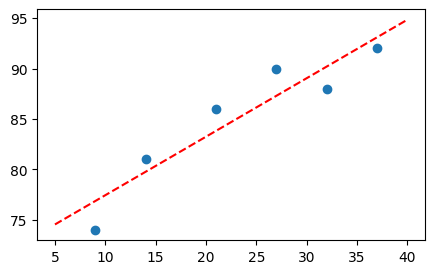

In [7]:
nx = np.arange(5, 45, 5)
nX = nx.reshape(-1, 1)
ny = lrModel.predict(nX)
print('테스트 데이터 : ', nx)
print('예측한 값    : ', ny.round(1))
plt.figure(figsize=(5,3))
plt.scatter(x,y)
plt.plot(nx, ny, 'r--');

### 3-변수 선형회귀(점수 예측)

In [8]:
import numpy as np

raw_data = np.array(
            [[73, 80, 75, 152],
             [93, 88, 93, 185],
             [89, 91, 90, 180],
             [96, 98, 100, 196],
             [73, 66, 70, 142],
             [53, 46, 55, 101],
             [69, 74, 77, 149],
             [47, 56, 60, 115],
             [87, 79, 90, 175],
             [79, 70, 88, 164],
             [69, 70, 73, 141],
             [70, 65, 74, 141],
             [93, 95, 91, 184],
             [79, 80, 73, 152],
             [70, 73, 78, 148],
             [93, 89, 96, 192],
             [78, 75, 68, 147],
             [81, 90, 93, 183],
             [88, 92, 86, 177],
             [78, 83, 77, 159],
             [82, 86, 90, 177],
             [86, 82, 89, 175],
             [78, 83, 85, 175],
             [76, 83, 71, 149],
             [96, 93, 95, 192]], dtype='f')

# raw_data = np.loadtxt('/content/drive/My Drive/ColabNB/Data/data-01.csv', delimiter=',')

x_data = raw_data[ :, 0:-1]  # 특징 배열. 2차원 테이블
t_data = raw_data[ :, -1]    # 레이블 벡터

# 데이터 차원 및 shape 확인
print("x_data.ndim = ", x_data.ndim, ", x_data.shape = ", x_data.shape)
print("t_data.ndim = ", t_data.ndim, ", t_data.shape = ", t_data.shape)
# print(x_data)
# print(t_data)

x_data.ndim =  2 , x_data.shape =  (25, 3)
t_data.ndim =  1 , t_data.shape =  (25,)


In [9]:
md_3var = LinearRegression()
md_3var.fit(x_data, t_data)

print("학습 데이터 점수: {}".format(md_3var.score(x_data, t_data)))

학습 데이터 점수: 0.9896615743637085


In [10]:
test_data = np.array([[90, 98, 81],
                      [81, 98, 90]])
pred = md_3var.predict(test_data)
print(pred.round(1))

[175.4 182.7]


In [11]:
print(md_3var.coef_)
print(md_3var.intercept_)

[0.35593864 0.54251873 1.1674442 ]
-4.336151


In [12]:
import pandas as pd
df = pd.DataFrame(data=x_data, columns=['국어', '영어', '수학'], index=range(1,26))
df['모의고사']=t_data
df

,국어,영어,수학,모의고사
1,73.0,80.0,75.0,152.0
2,93.0,88.0,93.0,185.0
3,89.0,91.0,90.0,180.0
4,96.0,98.0,100.0,196.0
5,73.0,66.0,70.0,142.0
6,53.0,46.0,55.0,101.0
7,69.0,74.0,77.0,149.0
8,47.0,56.0,60.0,115.0
9,87.0,79.0,90.0,175.0
10,79.0,70.0,88.0,164.0


In [13]:
df.describe()

,국어,영어,수학,모의고사
count,25.000000,25.000000,25.000000,25.000000
mean,79.040001,79.480003,81.480003,162.039993
std,12.279657,12.503733,11.765486,24.044195
min,47.000000,46.000000,55.000000,101.000000
25%,73.000000,73.000000,73.000000,148.000000
50%,79.000000,82.000000,85.000000,164.000000
75%,88.000000,89.000000,90.000000,180.000000
max,96.000000,98.000000,100.000000,196.000000


# 다항 회귀(Polynomial Regression)

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import numpy as np
import matplotlib.pyplot as plt

데이터 생성

$ x = -3.0 \sim 3.0 $의 실수 100개

$ y=0.5x^2+x+2+\alpha $ &ensp; where $ \alpha = -2.0$ ~ $2.0$

		X				y
[[ 2.24487796  7.31200727]
 [-0.94596694  1.6447175 ]
 [-0.59018182  2.59980073]
 [-2.60613513  3.90058933]
 [ 2.04555133  7.64558262]
 [-1.40228891  3.17113451]
 [ 0.39644118  4.04836016]
 [-2.40196673  3.4690167 ]
 [ 1.46046143  6.13907764]
 [ 2.22702879  7.29144162]]


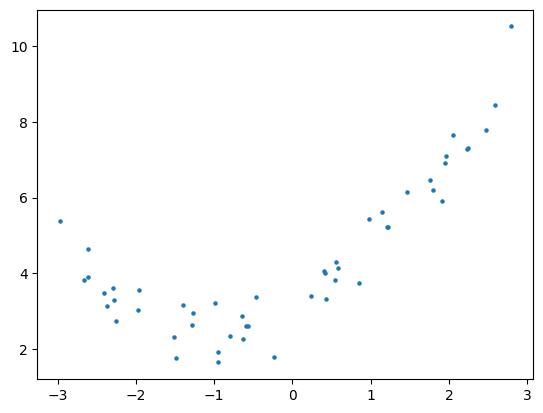

In [33]:
n = 50

X = 6 * np.random.rand(n, 1) - 3
y = 0.5 * X**2 + X + 2 + np.random.rand(n, 1)*2  # *1.5  *2  *2.5
print("\t\tX\t\t\t\ty"); print(np.hstack([X, y])[:10,:])

plt.scatter(X, y, s=5) ;

In [34]:
poly_features = PolynomialFeatures(degree=2, include_bias=False)  # 기본 다항식(기본 2차) 형태를 만들고
                                                                  # degree=3으로 하면?
X_poly = poly_features.fit_transform(X)
    # 새롭게 정의된 numpy 배열은 각 데이터를 다항 형태로 변형 --> 1차항 값, 2차항 값

print(X[:10,:])
print(poly_features.get_feature_names_out())  # [1차항특성, 2차항특성]
print(X_poly[:10,:])

[[ 2.24487796]
 [-0.94596694]
 [-0.59018182]
 [-2.60613513]
 [ 2.04555133]
 [-1.40228891]
 [ 0.39644118]
 [-2.40196673]
 [ 1.46046143]
 [ 2.22702879]]
['x0' 'x0^2']
[[ 2.24487796  5.03947704]
 [-0.94596694  0.89485345]
 [-0.59018182  0.34831458]
 [-2.60613513  6.79194031]
 [ 2.04555133  4.18428024]
 [-1.40228891  1.96641418]
 [ 0.39644118  0.15716561]
 [-2.40196673  5.76944418]
 [ 1.46046143  2.13294759]
 [ 2.22702879  4.95965722]]


In [35]:
polyModel = LinearRegression()

In [36]:
polyModel.fit(X_poly, y) ;

In [37]:
print(polyModel.coef_, polyModel.intercept_)

[[0.9854483  0.49855661]] [3.08336485]


In [38]:
import sympy as sym

x = sym.Symbol('x')
f = round(polyModel.coef_[0,1],2)*x**2 + round(polyModel.coef_[0,0],2)*x + round(polyModel.intercept_[0],2)
f

0.5*x**2 + 0.99*x + 3.08

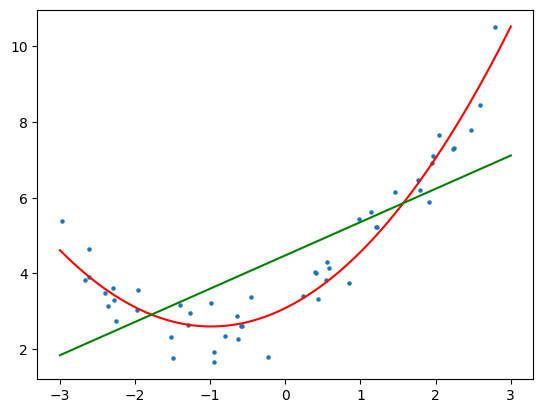

In [39]:
def func(x):
    return polyModel.coef_[0,1]*x**2 + polyModel.coef_[0,0]*x + polyModel.intercept_[0]

plt.scatter(X, y, s=5)

xx = np.linspace(-3, 3, 100).reshape(-1,1)
xx_poly = poly_features.fit_transform(xx)
yy = polyModel.predict(xx_poly)
# yy = fx(xx)
plt.plot(xx, yy, color='r')

linModel = LinearRegression()
linModel.fit(X, y)
plt.plot(xx, linModel.predict(xx), color='g')

### 과소 적합(Underfit), 과대 적합(Overfit)

Automatically created module for IPython interactive environment


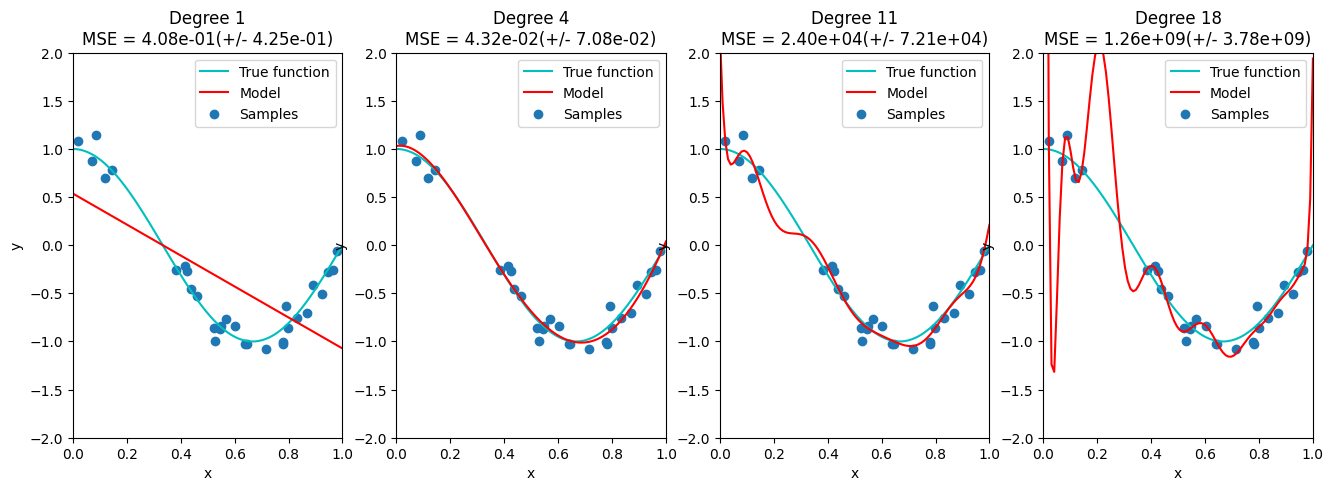

In [40]:
print(__doc__)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

np.random.seed(0)

n_samples = 30
degrees = [1, 4, 11, 18]

true_fun = lambda X: np.cos(1.5 * np.pi * X)
X = np.sort(np.random.rand(n_samples))
y = true_fun(X) + np.random.randn(n_samples) * 0.1

plt.figure(figsize=(16, 5))
for i in range(len(degrees)):
    plt.subplot(1, len(degrees), i + 1)
    # ax = plt.subplot(1, len(degrees), i + 1)
    # plt.setp(ax, xticks=(), yticks=())

    polynomial_features = PolynomialFeatures(degree=degrees[i],
                                             include_bias=False)
    linear_regression = LinearRegression()
    pipeline = Pipeline([("polynomial_features", polynomial_features),
                         ("linear_regression", linear_regression)])
    pipeline.fit(X[:, np.newaxis], y)

    # Evaluate the models using crossvalidation
    scores = cross_val_score(pipeline, X[:, np.newaxis], y,
                             scoring="neg_mean_squared_error", cv=10)

    X_test = np.linspace(0, 1, 100)
    plt.plot(X_test, true_fun(X_test), label="True function", c='c')
    plt.plot(X_test, pipeline.predict(X_test[:, np.newaxis]), label="Model", c='r')
    plt.scatter(X, y, label="Samples")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.xlim((0, 1))
    plt.ylim((-2, 2))
    plt.legend(loc="best")
    plt.title("Degree {}\nMSE = {:.2e}(+/- {:.2e})".format(
        degrees[i], -scores.mean(), scores.std()))
plt.show()